# Families (losses)

The **family** sets the loss $\rho(y,f)$ and therefore what the model targets.
Pass it via `family=`. The catalog mirrors `mboost`.

Response type $\rightarrow$ recommended family:

- **real-valued mean** $\rightarrow$ `Gaussian()` / `GaussReg()`
- **0/1 classification** $\rightarrow$ `Binomial()`
- **counts** $\rightarrow$ `Poisson()` / `NBinomial()`
- **positive, right-skewed** $\rightarrow$ `GammaReg()`
- **heavy tails / quantiles** $\rightarrow$ `Huber()` / `Laplace()` / `Quantile()` / `Expectile()`
- **ordered categories** $\rightarrow$ `PropOdds()`
- **survival** $\rightarrow$ `CoxPH()` / `Weibull()` / `Loglog()` / `Lognormal()`
- **multi-class** $\rightarrow$ `Multinomial()`
- **distributional (mean + scale + shape)** $\rightarrow$ LSS (location, scale
  and shape) families

```{list-table}
:header-rows: 1

* - Family
  - Target / loss
  - Response
* - `Gaussian()`
  - Mean, squared error
  - real
* - `GaussReg()`
  - The same model as `Gaussian()` under a second name
  - real
* - `Binomial()`
  - Half the log-odds, binomial deviance
  - 0/1
* - `Poisson()`
  - Log-mean, Poisson deviance
  - counts
* - `NBinomial()`
  - Negative-binomial (overdispersed counts)
  - counts
* - `Hurdle()`
  - Zero-truncated negative binomial: the positive-count part of a hurdle model
  - counts $> 0$
* - `GammaReg()`
  - Gamma regression (positive, skewed)
  - $> 0$
* - `Huber()` / `Laplace()`
  - Robust regression
  - real
* - `Quantile(tau)`
  - Quantile regression
  - real
* - `Expectile(tau)`
  - Expectile regression
  - real
* - `AdaExp()`
  - AdaBoost exponential loss
  - -1/1
* - `PropOdds()`
  - Proportional-odds (ordinal)
  - ordered
* - `CoxPH()`, `Weibull()`, `Loglog()`, `Lognormal()`
  - Survival (see [](../methodology/survival))
  - `Surv(time, status)`
* - `Multinomial()`
  - Multi-class (see [](multinomial.ipynb))
  - factor
* - `HingeLoss()`
  - Margin classification
  - -1/1
```

Use the capability table when a workflow needs diagnostics, AIC, CDFs, or
simulation support:

In [1]:
import mboostrs as mb
import polars as pl

mb.family_capabilities(output="polars").filter(
    pl.col("name").is_in(["Gaussian", "Binomial", "CoxPH", "GaussianLSS", "ZIPoLSS"])
).select(["name", "kind", "predict_response", "aic", "cdf", "diagnostics"])

name,kind,predict_response,aic,cdf,diagnostics
"""Binomial""","""standard""","""yes""","""partial""","""no""","""partial"""
"""CoxPH""","""standard_survival""","""partial""","""no""","""no""","""partial"""
"""Gaussian""","""standard""","""yes""","""partial""","""no""","""partial"""
"""GaussianLSS""","""lss""","""yes""","""no""","""yes""","""partial"""
"""ZIPoLSS""","""lss""","""yes""","""no""","""yes""","""partial"""


In [2]:
import numpy as np
rng = np.random.default_rng(11)
n = 400
x = rng.normal(size=n)

## Classification: `Binomial`

`Binomial` models a 0/1 response. Following `mboost`, its additive predictor
$f$ is half the log-odds, $P(y=1) = 1/(1+e^{-2f})$, so coefficients are on
the half-log-odds scale; `predict(type="response")` returns $P(y = 1)$.

In [3]:
p = 1 / (1 + np.exp(-(1.2 * x)))
y = (rng.uniform(size=n) < p).astype(float)
m = mb.glmboost("y ~ x", data={"x": x, "y": y}, family=mb.Binomial(),
                control=mb.boost_control(200, 0.1))
prob = m.predict(type="response")           # P(y = 1)
acc = np.mean((prob > 0.5) == (y == 1))
print("accuracy:", round(float(acc), 3))

accuracy: 0.718


## Ranking classification: `AUC`

`Binomial` targets calibrated probabilities. When you only care about **ranking**
— separating positives from negatives regardless of the probability scale — use
`AUC`, which directly optimizes a smoothed area-under-the-ROC-curve objective.
The response is `{0,1}` (or a two-level factor), the `offset` is $0$, and the
reported risk is $1 - \mathrm{AUC}$. The loss is a sum over positive/negative
**pairs**, so each iteration is $O(n^2)$ — fine for moderate $n$.

`AUC` accepts non-unit weights, so `cvrisk` and `stabsel` work for choosing the
stopping iteration. The survival ranking families `Gehan` and `Cindex` are
covered in [](survival.ipynb).

In [4]:
x2 = rng.normal(size=n)
lp = 1.2 * x - 0.8 * x2
y_auc = (rng.uniform(size=n) < 1 / (1 + np.exp(-lp))).astype(float)
data_auc = {"y": y_auc, "x": x, "x2": x2}

m_auc = mb.glmboost("y ~ x + x2", data=data_auc, family=mb.AUC(),
                    control=mb.boost_control(200, 0.1))
scores = m_auc.predict()
pos, neg = scores[y_auc == 1], scores[y_auc == 0]
emp_auc = float(np.mean(pos[:, None] > neg[None, :]))
print(f"risk (1 - AUC): start={m_auc.risk_[0]:.3f}  end={m_auc.risk_[-1]:.3f}")
print(f"empirical AUC of fitted scores: {emp_auc:.3f}")

# cvrisk selects the stopping iteration (uses the weighted gradient)
cv_auc = m_auc.cvrisk(type="subsampling", B=10, seed=1)
print("cvrisk(AUC) optimal mstop:", cv_auc.optimal_mstop)

risk (1 - AUC): start=1.000  end=0.182
empirical AUC of fitted scores: 0.818
cvrisk(AUC) optimal mstop: 35


/var/folders/pr/mdlxf70n2rl6445yj_0b0wx40000gn/T/ipykernel_44066/1268289168.py:8: UserWarning: predict() with default type='link' returns the link scale for AUC; pass type='response' for response scale.
  scores = m_auc.predict()


## Counts: `Poisson`

`Poisson` models the log of the mean of a count response.

In [5]:
mu = np.exp(0.5 + 0.7 * x)
yc = rng.poisson(mu).astype(float)
mp = mb.glmboost("y ~ x", data={"x": x, "y": yc}, family=mb.Poisson(),
                 control=mb.boost_control(200, 0.1))
print("fitted mean range:", np.round([mp.predict(type='response').min(),
                                      mp.predict(type='response').max()], 2))

fitted mean range: [ 0.26 18.73]


## Overdispersed counts: NBinomial

`NBinomial` models counts whose variance exceeds their mean, using a log
link for the mean and a size estimated at each boosting step. The fitted
`model.size` is the size in `Var(Y) = mu + mu**2 / size`; smaller size gives
more extra-Poisson variation. `model.nuisance()[0]` returns the same value.
statsmodels NB2 uses the reciprocal, `alpha = 1 / model.size`. In R,
`size(fit)` and `nuisance(fit)` return this size. `NBinomial()` estimates it
during fitting and rejects fixed `size`, `alpha` and `dispersion` arguments.

In [6]:
mu_nb = np.exp(0.5 + 0.7 * x)
# negative-binomial with overdispersion (theta = 2)
theta = 2.0
ynb = rng.negative_binomial(theta, theta / (mu_nb + theta)).astype(float)
mnb = mb.glmboost("y ~ x", data={"x": x, "y": ynb}, family=mb.NBinomial(),
                  control=mb.boost_control(200, 0.1))
print("NBinomial mean range:", np.round([mnb.predict(type='response').min(),
                                          mnb.predict(type='response').max()], 2))

NBinomial mean range: [ 0.25 18.3 ]


### Poisson and NBinomial on overdispersed data

Fit both families to `ynb` (which has real overdispersion by construction)
and compare. Poisson has no way to represent excess variance, so the two
should agree on the mean but only `NBinomial` accounts for the extra spread:

In [7]:
m_pois_same = mb.glmboost("y ~ x", data={"x": x, "y": ynb}, family=mb.Poisson(),
                          control=mb.boost_control(200, 0.1))
m_nb_same = mb.glmboost("y ~ x", data={"x": x, "y": ynb}, family=mb.NBinomial(),
                        control=mb.boost_control(200, 0.1))

pred_pois = m_pois_same.predict(type="response")
pred_nb = m_nb_same.predict(type="response")
print(f"mean |Poisson pred - NBinomial pred| = {np.mean(np.abs(pred_pois - pred_nb)):.4f}")
print(f"empirical var/mean ratio in the data = {ynb.var() / ynb.mean():.2f}  "
      f"(1.0 is what Poisson assumes)")


mean |Poisson pred - NBinomial pred| = 0.0874
empirical var/mean ratio in the data = 5.12  (1.0 is what Poisson assumes)


The two families' fitted means agree closely — the mean structure
$\log \mu = \beta_0 + \beta_1 x$ is the same in both. What differs is the variance each family assumes:
Poisson fixes $\operatorname{Var}(Y)=\mu$, but this data's empirical
variance-to-mean ratio is well above 1 (it was generated with a
negative-binomial dispersion). Point predictions from Poisson are close to
NBinomial's here (mean absolute difference 0.087), with an empirical
variance-to-mean ratio of 5.12. A Poisson model assumes a ratio of 1, so any
interval, likelihood or test derived from it treats the data as less variable
than they are; `NBinomial`'s size parameter absorbs the excess variance.

## Gamma regression: `GammaReg`

For positive, right-skewed responses (costs, waiting times, rainfall):

In [8]:
mu_g = np.exp(1.0 + 0.5 * x)
yg = rng.gamma(shape=3, scale=mu_g/3).astype(float)        # shape=3 $\rightarrow$ moderate skew
mg = mb.glmboost("y ~ x", data={"x": x, "y": yg}, family=mb.GammaReg(),
                  control=mb.boost_control(200, 0.1))
print("Gamma mean range:", np.round([mg.predict(type='response').min(),
                                      mg.predict(type='response').max()], 2))

Gamma mean range: [ 0.86 13.76]


## Proportional odds: `PropOdds`

For ordered categorical responses, `PropOdds` models cumulative logits with
a common slope but category-specific intercepts. Here the outcome has three
ordered levels (low $\rightarrow$ medium $\rightarrow$ high):

In [9]:
x_p = rng.normal(size=n)
eta_p = 1.5 * x_p
p1 = 1 / (1 + np.exp(-(eta_p - 0.5)))           # P(low)
p2 = 1 / (1 + np.exp(-(eta_p + 0.5))) - p1     # P(medium)
y_p = np.array([np.argmax(rng.multinomial(1, [p1[i], p2[i], 1-p1[i]-p2[i]])) + 1
                for i in range(n)]).astype(float)
m_po = mb.glmboost("y ~ x", data={"x": x_p, "y": y_p}, family=mb.PropOdds(n_levels=3),
                   control=mb.boost_control(200, 0.1))
print("PropOdds correct:", round(float(np.mean(
    np.argmax(m_po.predict(type="response"), axis=1) + 1 == y_p)), 3))

PropOdds correct: 0.685


## Robust and quantile regression

The same predictor is fitted with three losses: squared error targets the conditional mean, `Quantile(tau=0.5)` the conditional median, and `Huber` a robust location.

Quantile offsets follow R's frequency-weight convention. For responses
$[1,2,3,4,5]$ with weights $[1,1,1,1,10]$, the conceptual expanded sample
has 14 values; its type-7 median lies halfway between the seventh and eighth
values, both 5, so the offset is 5. `mboostrs` locates those order statistics
from cumulative frequencies without constructing the 14 response copies (or, for large weights,
billions). Thus memory remains $O(n)$ while retaining the
same type-7 interpolation as R.

In [10]:
yr = 2 * x + rng.standard_t(df=2, size=n)         # heavy-tailed noise + outliers
fits = {
    "mean (Gaussian)":  mb.Gaussian(),
    "median (Quantile 0.5)": mb.Quantile(tau=0.5),
    "robust (Huber)":   mb.Huber(),
}
for label, fam in fits.items():
    mm = mb.glmboost("y ~ x", data={"x": x, "y": yr}, family=fam,
                     control=mb.boost_control(200, 0.1))
    print(f"{label:24s} slope ≈ {mm.coef().get('x', 0):.3f}")

mean (Gaussian)          slope ≈ 1.878
median (Quantile 0.5)    slope ≈ 1.984
robust (Huber)           slope ≈ 1.948


The noise is Student $t$ with 2 degrees of freedom, which produces occasional
large outliers; the true slope is 2. The outliers pull the Gaussian slope to
1.878, while the median and Huber fits give 1.984 and 1.948.

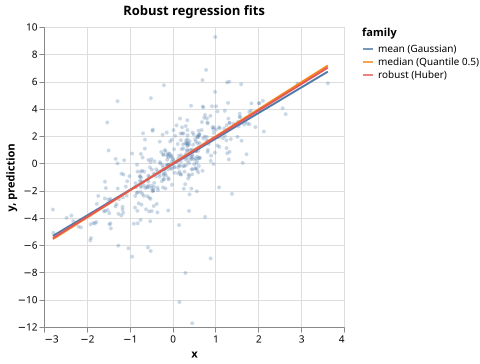

In [11]:
import altair as alt
import polars as pl
x_sorted = np.sort(x)
pdf_lines = pl.DataFrame({"x": x_sorted})
for label, fam in fits.items():
    mm = mb.glmboost("y ~ x", data={"x": x, "y": yr}, family=fam,
                     control=mb.boost_control(200, 0.1))
    pred = mm.predict(newdata={"x": x_sorted})
    pdf_lines = pdf_lines.with_columns(pl.Series(label, pred))
pdf_pts = pl.DataFrame({"x": x, "y": yr})
pts = alt.Chart(pdf_pts).mark_circle(opacity=0.3, size=15).encode(x="x", y="y")
pdf_melted = pdf_lines.unpivot(
    index="x", on=list(fits.keys()),
    variable_name="family", value_name="prediction"
)
lines = alt.Chart(pdf_melted).mark_line(strokeWidth=2).encode(
    x="x", y="prediction:Q", color="family:N"
)
(pts + lines).properties(title="Robust regression fits")

## Properties fixed by the family

The family determines the loss, link, inverse link, offset, and negative
gradient. Each determines how to interpret or compute a fitted value.

| | What it is | Where you meet it |
|---|---|---|
| **Loss** | the function $\rho(y, f)$ the path minimises | `fit.risk` is its running total |
| **Link** | the scale the model is additive on | `predict(type="link")` returns it |
| **Inverse link** | the map back to the response scale | `predict(type="response")` applies it |
| **Offset** | the constant the path starts from | `fit.offset` |
| **Negative gradient** | the working response each step regresses on | `fit.residuals(type="working")` |

For `Binomial` the link scale is half the log-odds, so `predict(type="link")`
returns a number $f$ on $(-\infty, \infty)$ with $P(y=1) = 1/(1+e^{-2f})$, and
`type="response"` returns that probability.
For `Poisson` the link is the log, so the response-scale prediction is a
positive rate. Reading a link-scale number as a probability or a rate is an error.

`fit.likelihood_contract()` reports which likelihood-based outputs (log
likelihood, AIC, distribution functions) the fitted family provides, and
`fit.residual_kinds()` which residual definitions it can produce.

### Operations unavailable for some families

Families differ in their supported operations. Unsupported operations raise a
named error rather than returning an unusable value:

- `Gehan`, `Cindex` and `AUC` optimise a **ranking** objective, so there is no
  likelihood: `logLik()` and `aic()` raise `NotImplementedError`.
- `GammaReg` estimates the gamma shape while boosting; `nuisance()` returns
  it, and the dispersion a Gamma GLM reports is its reciprocal.
- `Multinomial` is fitted with `gamboost` only; `glmboost` refuses it, and a
  linear multinomial model is written with `bols` terms under `gamboost`.
- The survival families compute the likelihood of $\log T$, so their
  `logLik` is not comparable with one for $T$.

`fit.parity_notes()` lists the deviations that apply to a given fit, and says
for each whether R `mboost` shares it.


## Families in R

The core standard families are available in the R binding with the same names:

```r
library(mboostrs)
set.seed(11)
n <- 400; x <- rnorm(n)

# Binomial classification
p <- 1 / (1 + exp(-(1.2 * x)))
y <- as.numeric(runif(n) < p)
m_binom <- glmboost(y ~ x, data = data.frame(x, y), family = Binomial(),
                    control = boost_control(200, 0.1))
prob <- predict(m_binom, type = "response")
cat("Binomial accuracy:", mean((prob > 0.5) == (y == 1)), "\n")

# Poisson counts
mu <- exp(0.5 + 0.7 * x)
yc <- rpois(n, mu)
m_pois <- glmboost(y ~ x, data = data.frame(x, y = yc), family = Poisson(),
                   control = boost_control(200, 0.1))

# Quantile regression
yr <- 2 * x + rt(n, df = 2)
m_q <- glmboost(y ~ x, data = data.frame(x, y = yr), family = Quantile(tau = 0.5),
                control = boost_control(200, 0.1))
cat("Quantile slope:", round(coef(m_q)["x"], 3), "\n")
```

## Distributional families

For LSS (location, scale and shape) models, the family describes an entire
response distribution and usually has several parameters, each with its own
additive predictor:

```{list-table}
:header-rows: 1

* - Data shape
  - Example families
  - Typical diagnostic
* - Location and scale
  - `GaussianLSS`, `GammaLSS`, `StudentTLSS`, `LogNormalLSS`
  - prediction intervals, quantile residuals
* - Counts and zero inflation
  - `PoissonLSS`, `NBinomialLSS`, `ZIPoLSS`, `ZINBLSS`
  - PIT, deviance increments
* - Semicontinuous (zeros plus a positive part)
  - `ZeroAdjustedGammaLSS`, `ZeroAdjustedPoissonLSS`
  - fitted zero probability against the observed zero rate
* - Bounded or compositional
  - `BetaLSS`, `DirichletLSS`
  - density/CDF support where available
* - Shape and tail control
  - `BCCGLSS` (Box-Cox Cole-Green), `BCTLSS` (Box-Cox $t$), `BCPELSS`
    (Box-Cox power exponential), `JSULSS` (Johnson's SU), `PIGLSS`
    (Poisson-inverse Gaussian, for counts), `Pareto2LSS` (Pareto type II),
    `LogisticLSS`, `InverseGaussianLSS`, `GumbelLSS`
  - capability-dependent
```

See [](gamboostlss.ipynb) for fitting and [](diagnostics.ipynb) for distributional
diagnostics.

Part II ([](../methodology/families)) tabulates each family's loss, negative
gradient, and offset.